# Exploratory Data Analysis — Heart Disease (4-site UCI dataset)

This notebook explores the combined Cleveland + Hungarian + Switzerland + VA
Long Beach dataset (918 rows after cleaning). The four-site combination is
deliberately harder than the common 303-row Cleveland-only version: it has
heavy, **site-dependent** missingness and a **site shift** in feature
distributions, both explored below.

All cleaning logic lives in `src/heart_mlops/data/clean.py` (called here, not
duplicated) so this notebook and the pipeline never disagree.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from heart_mlops.config import REPORTS_FIGURES_DIR
from heart_mlops.data.clean import clean, data_quality_summary, load_combined_raw

REPORTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.titleweight"] = "bold"

SITE_ORDER = ["cleveland", "hungarian", "switzerland", "va"]
SITE_PALETTE = dict(zip(SITE_ORDER, sns.color_palette("Set2", 4), strict=True))


def savefig(fig, name):
    path = REPORTS_FIGURES_DIR / name
    fig.savefig(path, bbox_inches="tight")
    print(f"Saved {path}")


raw = load_combined_raw()
df = clean(raw)
df.shape

(918, 16)

## 1. Data overview

In [2]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target,site
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0,0,cleveland
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,2,1,cleveland
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1,1,cleveland
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0,0,cleveland
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0,0,cleveland


In [3]:
df.dtypes

age         float64
sex           Int64
cp            Int64
trestbps    float64
chol        float64
fbs           Int64
restecg       Int64
thalach     float64
exang         Int64
oldpeak     float64
slope         Int64
ca            Int64
thal          Int64
num           Int64
target         int8
site         object
dtype: object

In [4]:
summary = data_quality_summary(df)
summary

,site,n_rows,missing_pct_age,missing_pct_sex,missing_pct_cp,missing_pct_trestbps,missing_pct_chol,missing_pct_fbs,missing_pct_restecg,missing_pct_thalach,missing_pct_exang,missing_pct_oldpeak,missing_pct_slope,missing_pct_ca,missing_pct_thal,target_positive_pct
0,cleveland,303,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.3,0.7,45.9
1,hungarian,293,0.0,0.0,0.0,0.3,7.5,2.7,0.3,0.3,0.3,0.0,64.5,99.0,90.4,36.2
2,switzerland,123,0.0,0.0,0.0,1.6,100.0,61.0,0.8,0.8,0.8,4.9,13.8,95.9,42.3,93.5
3,va,199,0.0,0.0,0.0,28.6,28.1,3.5,0.0,26.6,26.6,28.1,50.8,99.0,82.9,74.4
4,ALL,918,0.0,0.0,0.0,6.5,21.9,9.8,0.2,6.0,6.0,6.8,33.4,66.3,52.7,55.3


**What this shows:** Cleveland is the only site with (nearly) complete
records. Hungarian, Switzerland and VA each have severe missingness in at
least one column (`ca`, `thal`, and -- for VA -- `trestbps`/`thalach`/`exang`/
`oldpeak` as well). This single table is why "impute everything the same way
regardless of site" would be a mistake, and is the main evidence behind the
`ca`/`thal`/`slope` feature decisions in `docs/DECISIONS.md`.

## 2. Missingness heatmap by site

**What this drives:** which columns can realistically be used as model
features without just re-encoding "which site is this row from".

Saved /Users/ssvmindsprivatelimited/Desktop/MTech/MLOps/MLOps_S1-26_AIMLZG523_Assignment1/reports/figures/01_missingness_heatmap.png


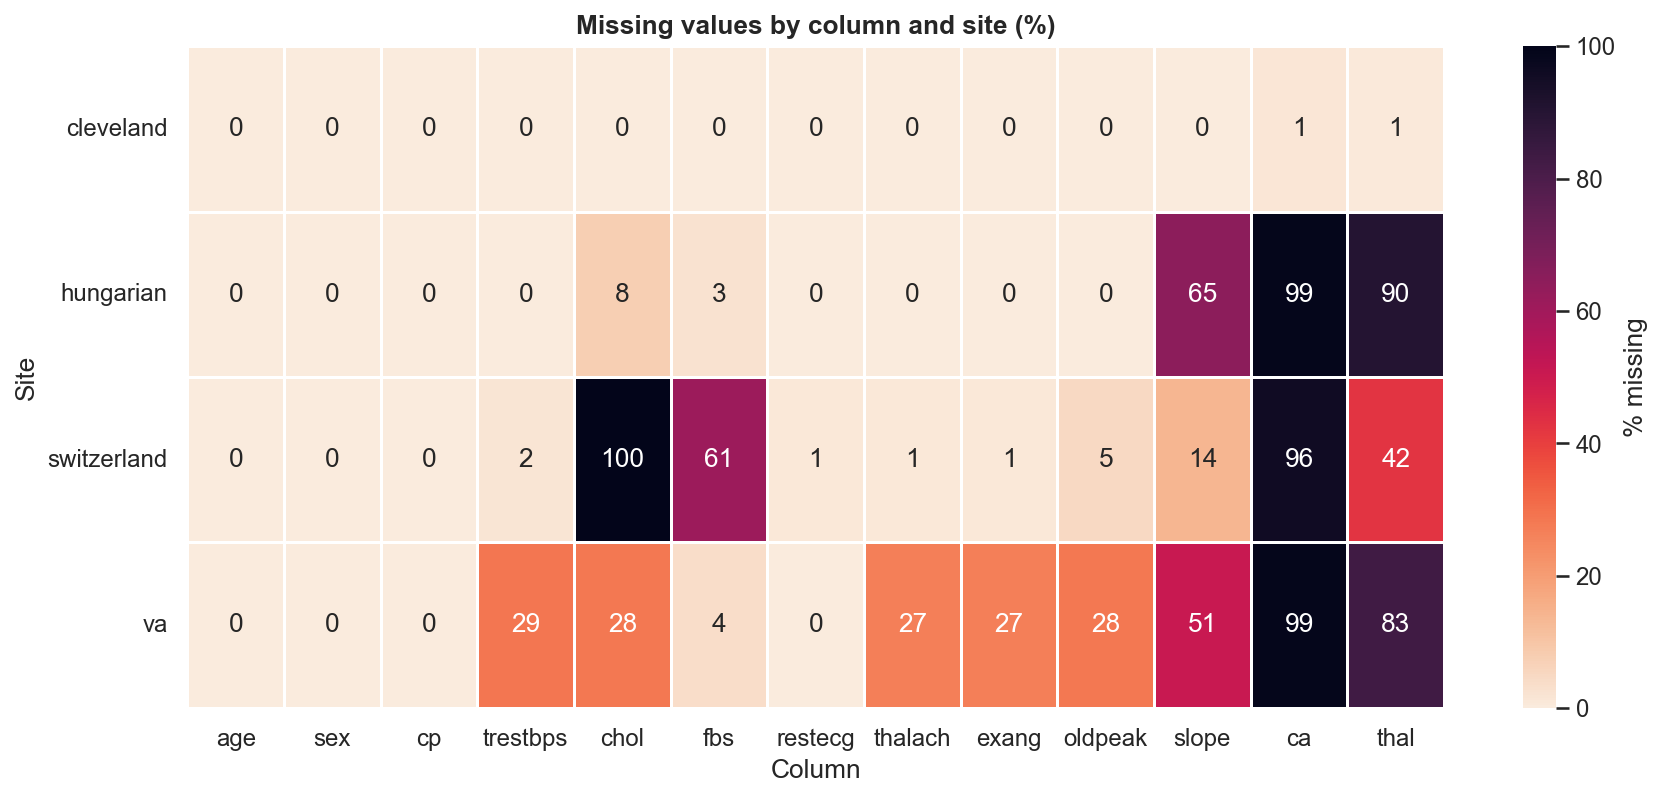

In [5]:
feature_cols = [c for c in df.columns if c not in ("num", "target", "site")]
missing_pct = (
    df.groupby("site")[feature_cols].apply(lambda g: g.isna().mean() * 100).loc[SITE_ORDER]
)

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(
    missing_pct,
    annot=True,
    fmt=".0f",
    cmap="rocket_r",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "% missing"},
    ax=ax,
    linewidths=0.5,
    linecolor="white",
)
ax.set_title("Missing values by column and site (%)")
ax.set_xlabel("Column")
ax.set_ylabel("Site")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
savefig(fig, "01_missingness_heatmap.png")
plt.show()

**Interpretation:** `ca` and `thal` are >90% missing in Hungarian and VA,
and `thal` is 42% missing even in Switzerland. `slope` is missing roughly
half the time outside Cleveland. `chol` is 100% missing in Switzerland --
this is entirely the zero-value cleaning rule (every Switzerland `chol`
reading was recorded as 0, i.e. not measured, not a real value of zero).
VA stands out for being incomplete across *several* columns at once
(`trestbps`, `chol`, `thalach`, `exang`, `oldpeak`, `slope`), unlike
Switzerland and Hungarian, which are each missing in a narrower set of
columns. This directly motivates per-site imputation diagnostics rather than
a single blanket strategy, and supports dropping `ca` (near-total absence
outside Cleveland leaves almost nothing to impute from).

## 3. Class balance — overall and per site

**What this drives:** whether class weighting / threshold selection needs to
account for site-specific prevalence differences, and confirms stratification
choices for cross-validation.

Saved /Users/ssvmindsprivatelimited/Desktop/MTech/MLOps/MLOps_S1-26_AIMLZG523_Assignment1/reports/figures/02_class_balance.png


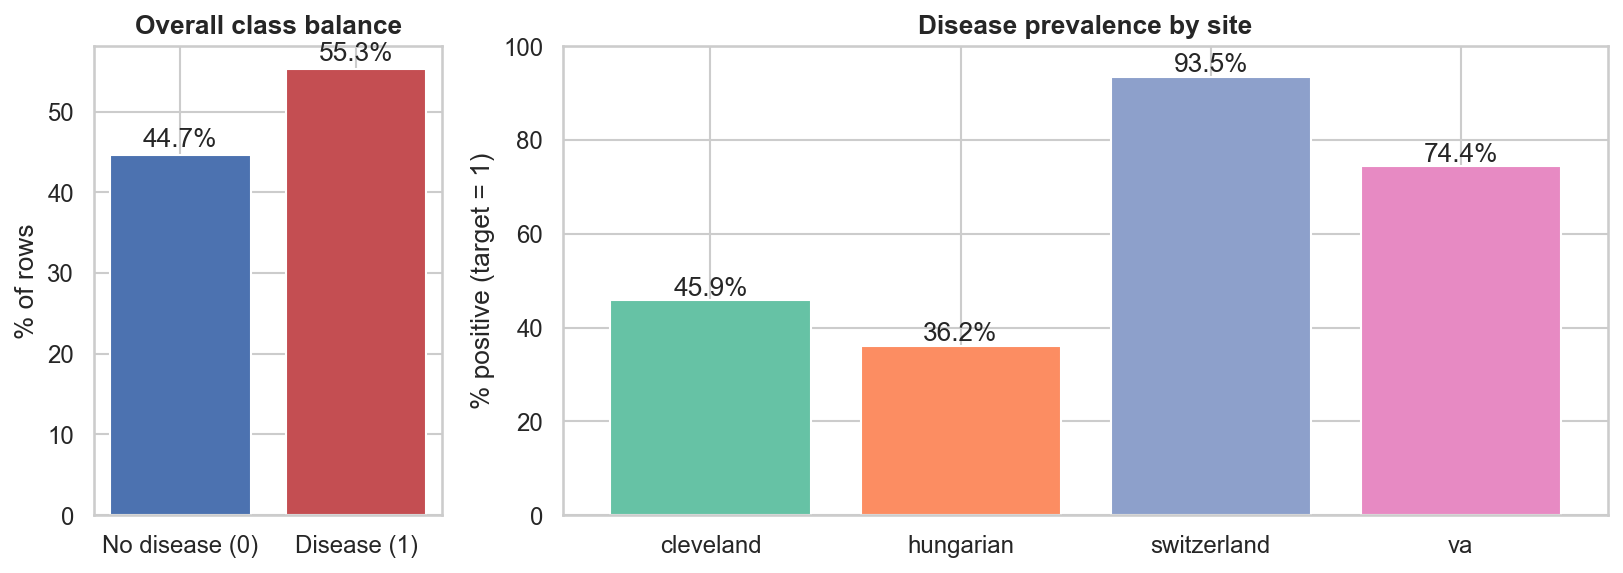

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 3]})

overall = df["target"].value_counts(normalize=True).sort_index() * 100
axes[0].bar(["No disease (0)", "Disease (1)"], overall.values, color=["#4C72B0", "#C44E52"])
axes[0].set_ylabel("% of rows")
axes[0].set_title("Overall class balance")
for i, v in enumerate(overall.values):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center")

site_balance = (df.groupby("site")["target"].mean() * 100).loc[SITE_ORDER]
bars = axes[1].bar(
    site_balance.index, site_balance.values, color=[SITE_PALETTE[s] for s in site_balance.index]
)
axes[1].set_ylabel("% positive (target = 1)")
axes[1].set_title("Disease prevalence by site")
axes[1].set_ylim(0, 100)
for bar, v in zip(bars, site_balance.values, strict=True):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.1f}%", ha="center")

fig.tight_layout()
savefig(fig, "02_class_balance.png")
plt.show()

**Interpretation:** the overall class balance (55.3% positive) looks
close to even, but that hides enormous **per-site prevalence shift**:
Switzerland is 93.5% positive and VA is 74.4% positive, while Hungarian is
only 36.2% positive. A model trained mostly on Hungarian-like prevalence and
evaluated on Switzerland (or vice versa) would see a very different operating
point purely from base-rate shift, independent of any real generalisation
failure. This is exactly what the leave-one-site-out evaluation (Phase 3) is
designed to expose, and it argues for stratifying the hold-out split on
`target` (done) while watching per-site recall separately rather than trusting
a single pooled number.

## 4. Numeric feature distributions by target

**What this drives:** which continuous features look informative for a
linear model (Logistic Regression) by eye, before any formal importance
analysis in Phase 3.

Saved /Users/ssvmindsprivatelimited/Desktop/MTech/MLOps/MLOps_S1-26_AIMLZG523_Assignment1/reports/figures/03_numeric_distributions.png


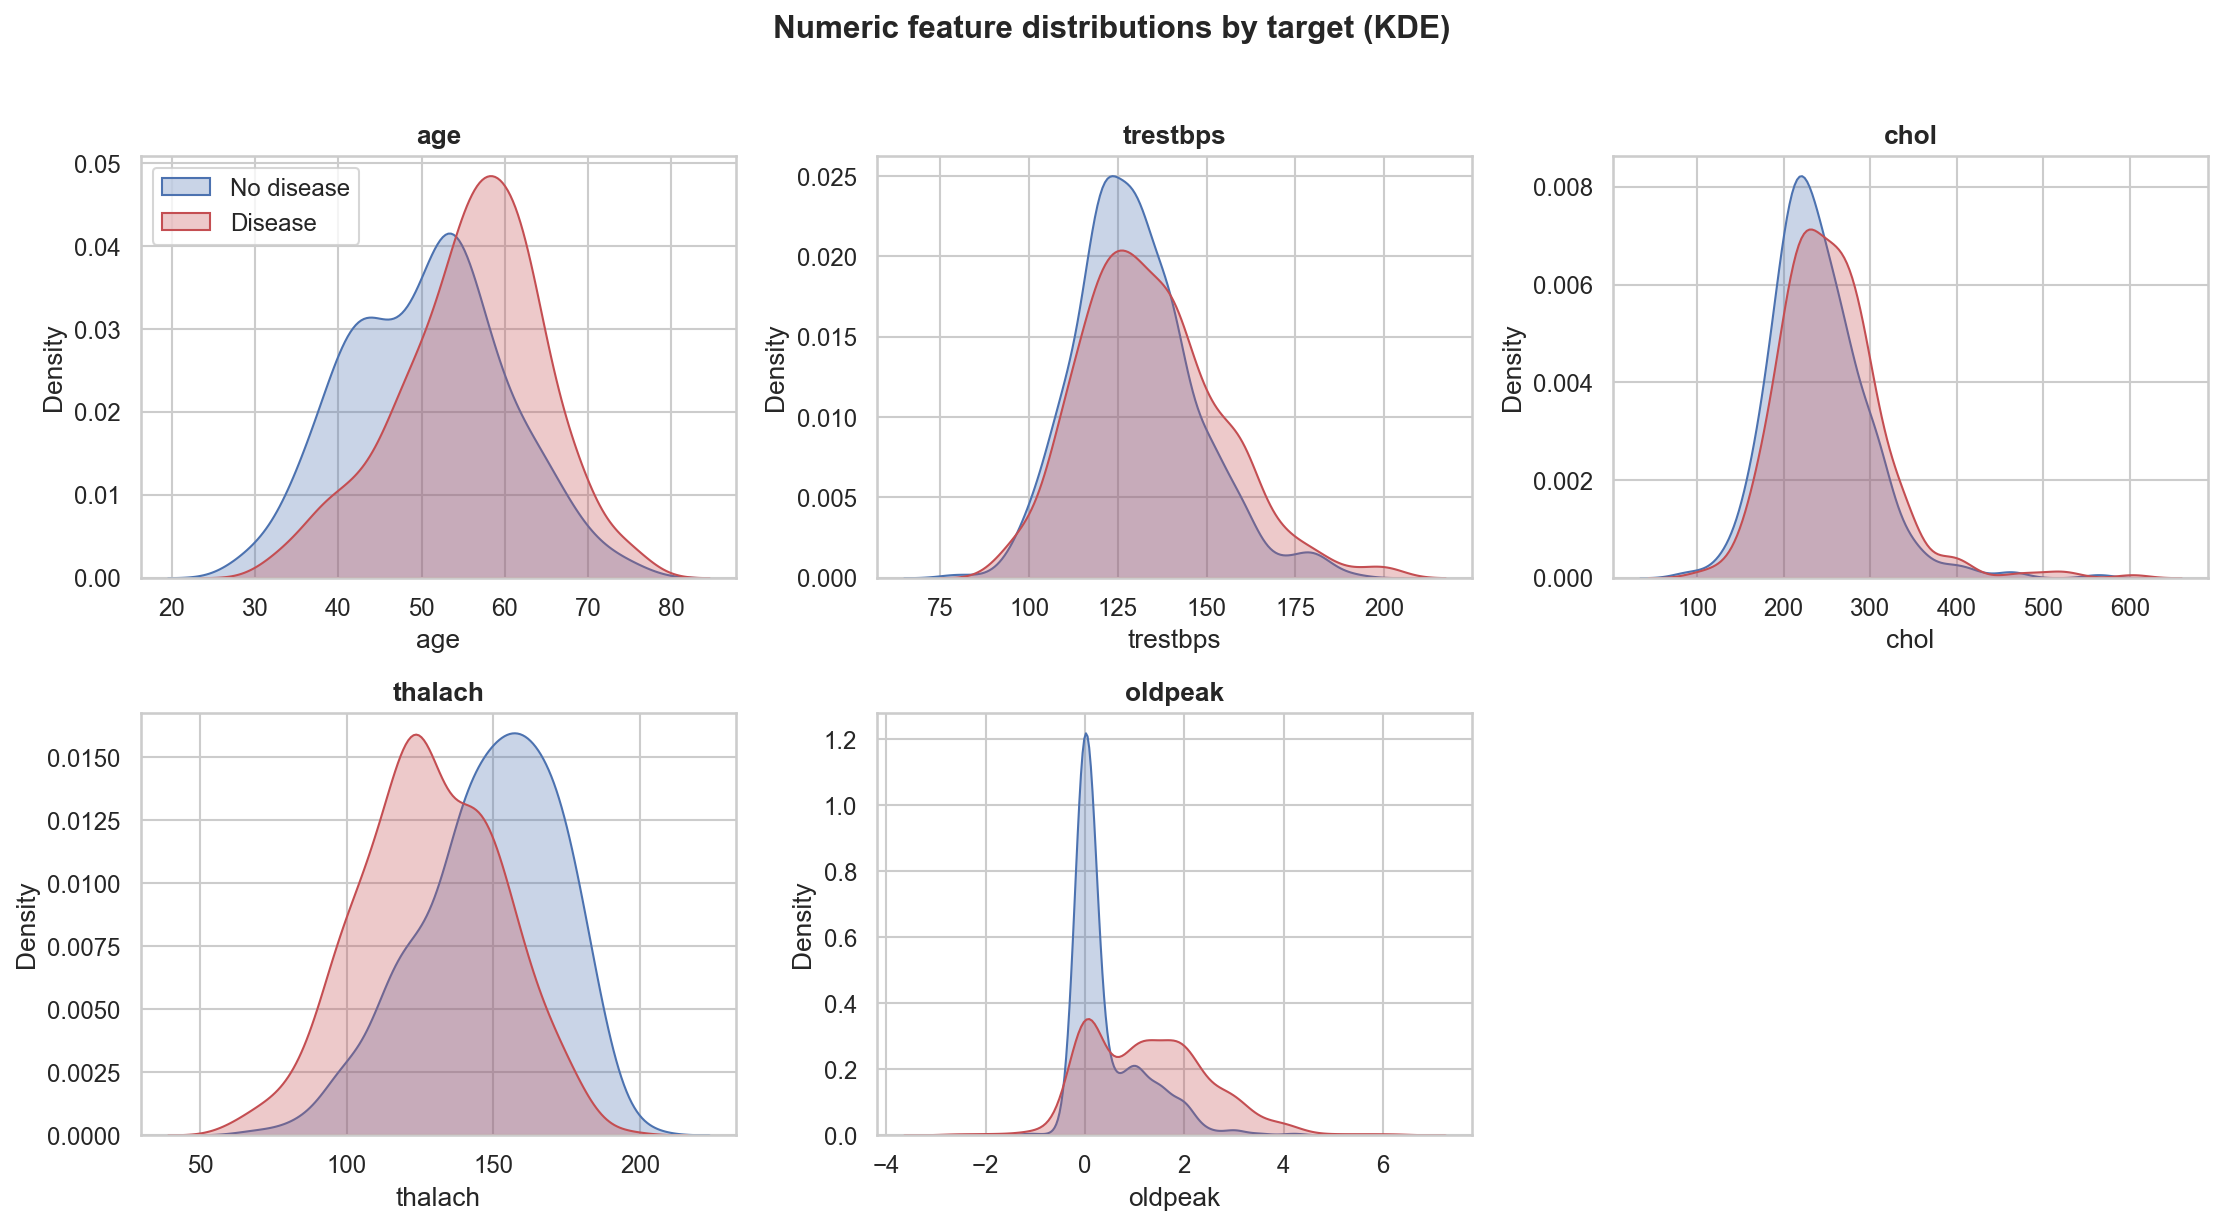

In [7]:
continuous_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, col in zip(axes, continuous_cols, strict=False):
    for target_val, color, label in [(0, "#4C72B0", "No disease"), (1, "#C44E52", "Disease")]:
        data = df.loc[df["target"] == target_val, col].dropna()
        sns.kdeplot(
            data, ax=ax, color=color, label=label, fill=True, alpha=0.3, warn_singular=False
        )
    ax.set_title(col)
    ax.set_xlabel(col)
axes[0].legend()
axes[-1].axis("off")
fig.suptitle("Numeric feature distributions by target (KDE)", y=1.02, fontweight="bold")
fig.tight_layout()
savefig(fig, "03_numeric_distributions.png")
plt.show()

**Interpretation:** `oldpeak` (ST depression) and `thalach` (max heart
rate achieved) show the clearest separation -- higher `oldpeak` and lower
`thalach` both skew toward the disease-positive class, consistent with known
clinical risk indicators. `age` and `trestbps` show only a mild rightward
shift for the positive class. `chol`'s distribution should be read cautiously
here: with 100% of Switzerland's values now missing (cleaned from the
zero-value artefact) and 28% of VA's, the remaining `chol` values are
disproportionately from Cleveland and Hungarian, so this plot is not a clean
cross-site picture.

## 5. Categorical feature counts by target

**What this drives:** which categorical features carry visibly different
target rates across their levels, worth keeping even with missingness.

Saved /Users/ssvmindsprivatelimited/Desktop/MTech/MLOps/MLOps_S1-26_AIMLZG523_Assignment1/reports/figures/04_categorical_counts.png


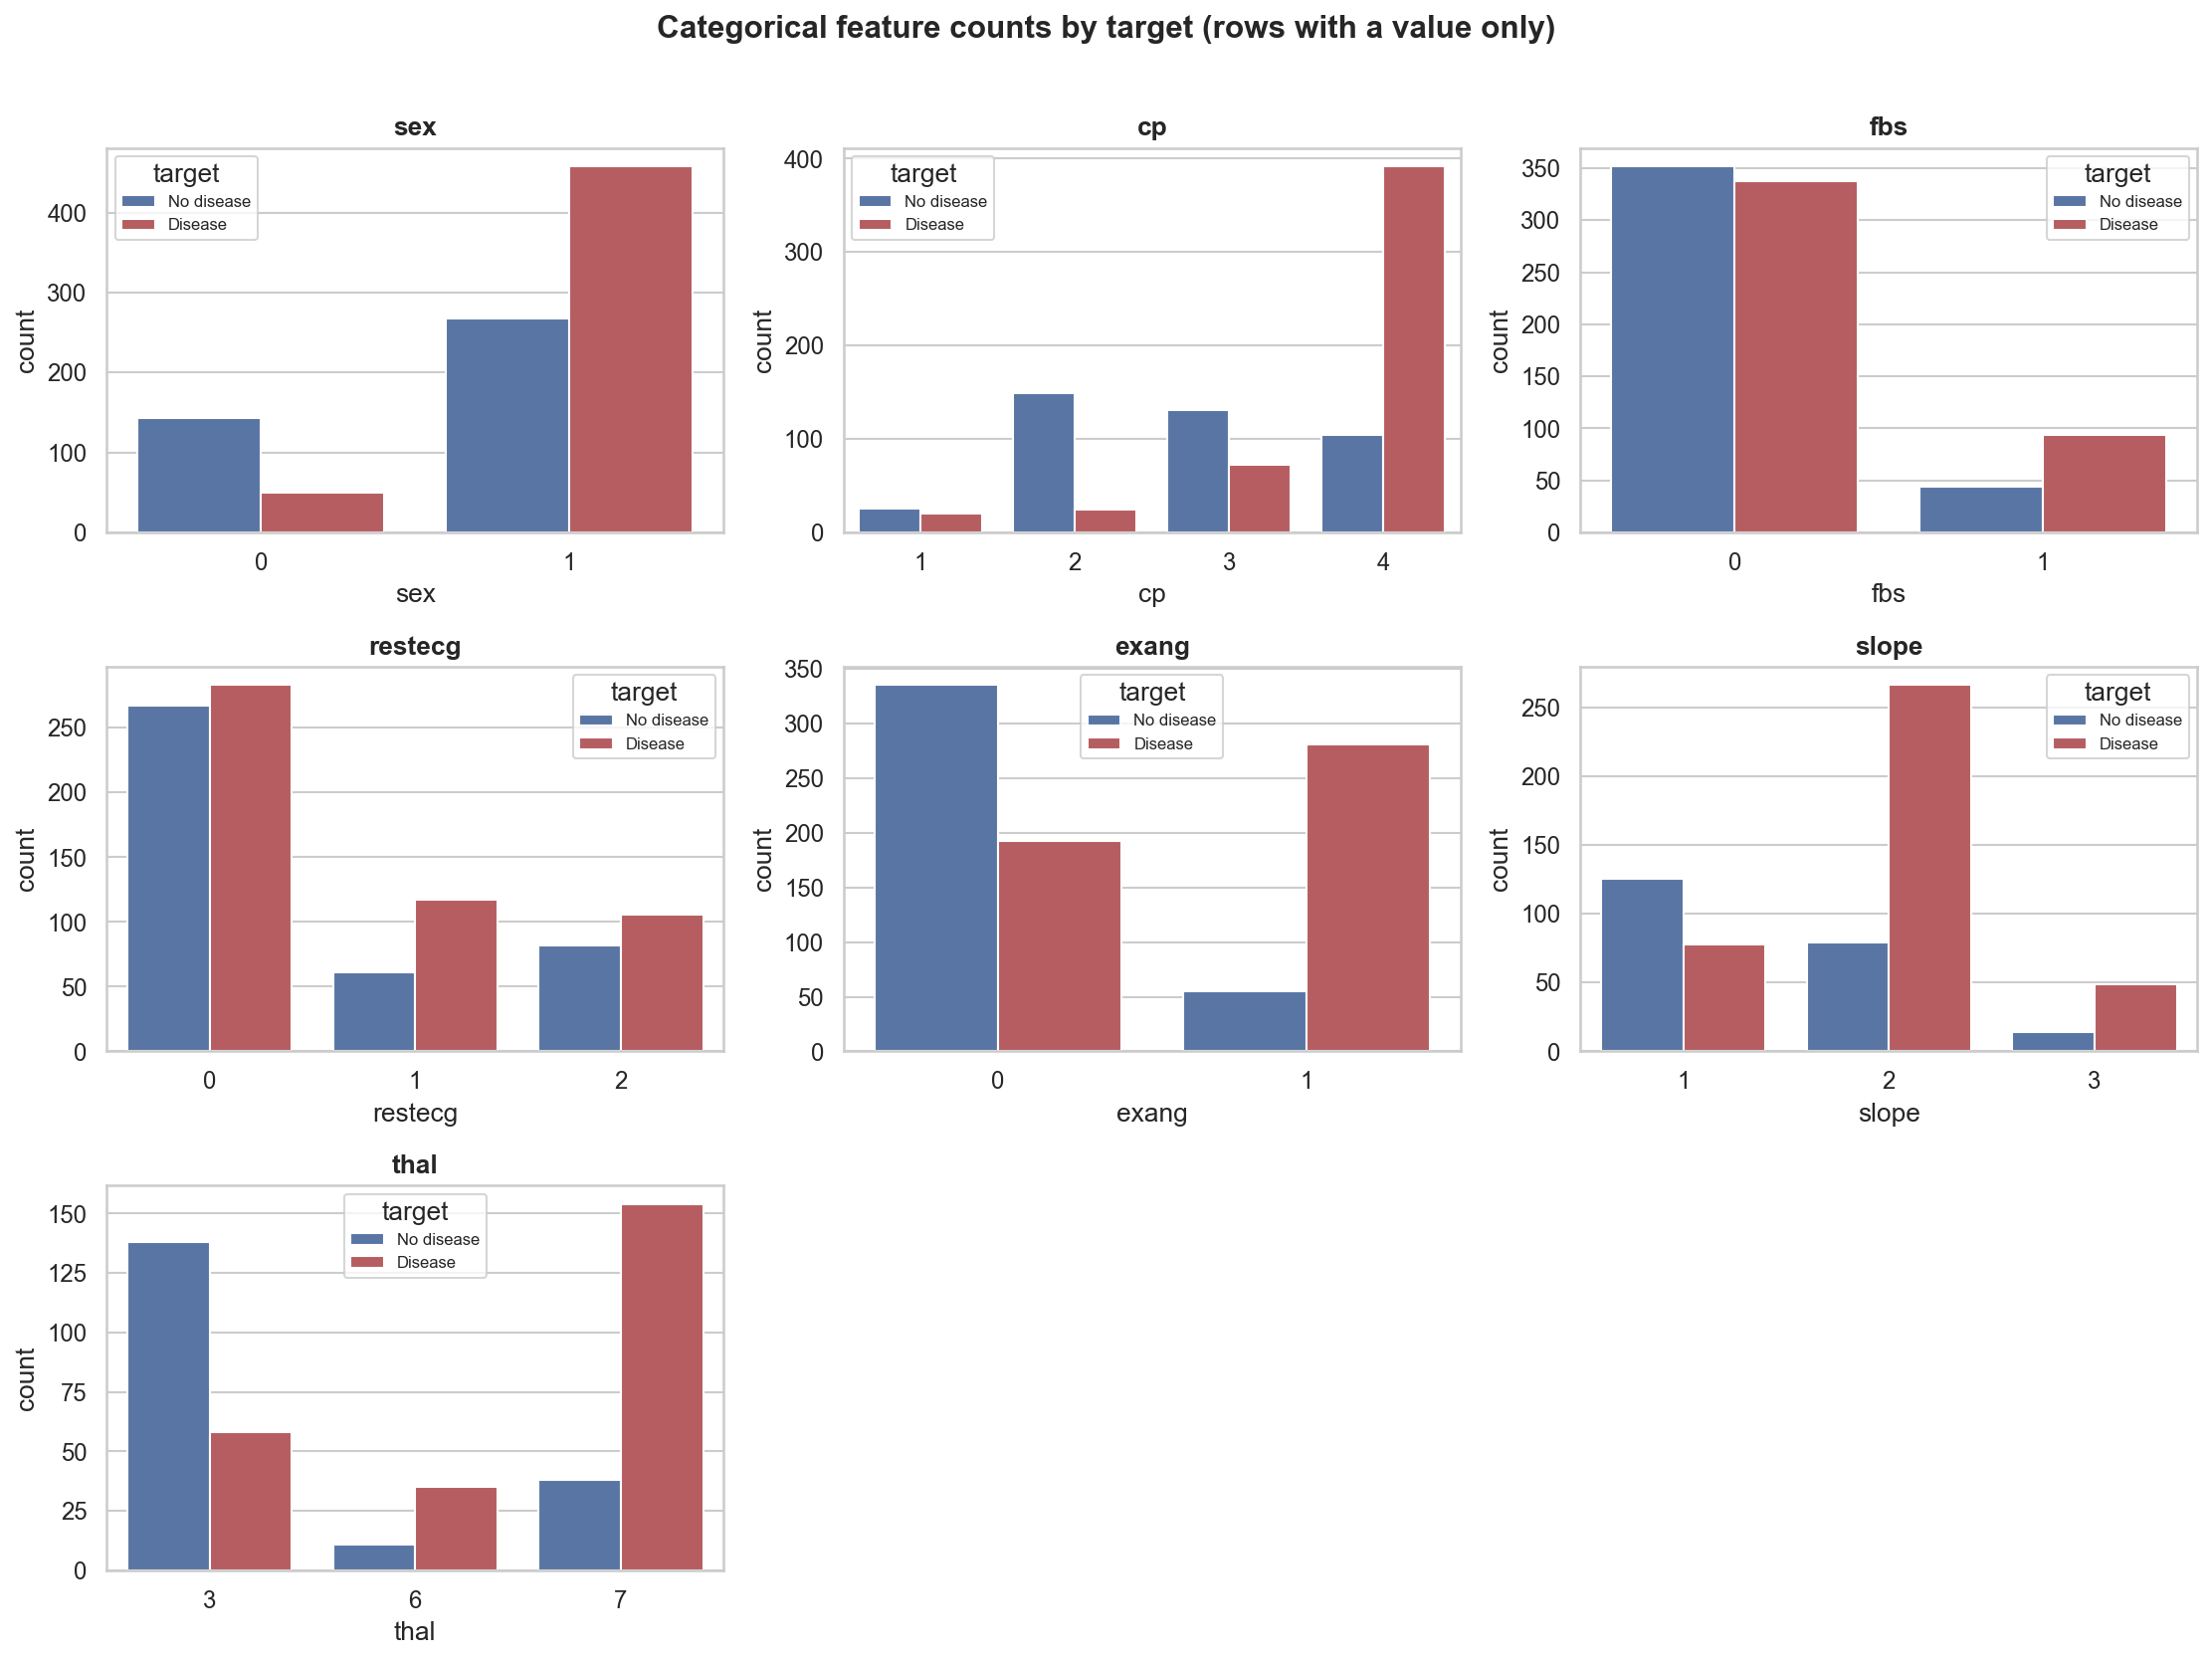

In [8]:
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.ravel()
for ax, col in zip(axes, categorical_cols, strict=False):
    plot_df = df[[col, "target"]].dropna()
    sns.countplot(data=plot_df, x=col, hue="target", ax=ax, palette={0: "#4C72B0", 1: "#C44E52"})
    ax.set_title(col)
    ax.legend(title="target", labels=["No disease", "Disease"], fontsize=8)
for ax in axes[len(categorical_cols) :]:
    ax.axis("off")
fig.suptitle(
    "Categorical feature counts by target (rows with a value only)", y=1.01, fontweight="bold"
)
fig.tight_layout()
savefig(fig, "04_categorical_counts.png")
plt.show()

**Interpretation:** `exang` (exercise-induced angina) and `cp` (chest
pain type) show the starkest split -- `exang = 1` and `cp = 4` (asymptomatic)
both skew heavily toward disease-positive, again matching clinical
expectation. `sex` shows male rows skew more disease-positive than female
rows in this dataset. Note these counts are **rows with a non-missing value
only** -- for `thal` and `slope` that means a minority of the Hungarian/VA
rows are represented here at all, which should temper how strongly we read
those two panels.

## 6. Correlation heatmap

**What this drives:** redundancy among numeric features (relevant for the
Logistic Regression baseline) and a first look at target association.
Pearson correlation is only valid for the continuous columns and the binary
target; it is **not** an appropriate measure for the multi-level categorical
columns (`cp`, `restecg`, `slope`, `thal`), whose integer codes are not
ordinal in a way Pearson can interpret. A Cramér's V heatmap is added
separately for those.

Saved /Users/ssvmindsprivatelimited/Desktop/MTech/MLOps/MLOps_S1-26_AIMLZG523_Assignment1/reports/figures/05_correlation_heatmap_pearson.png


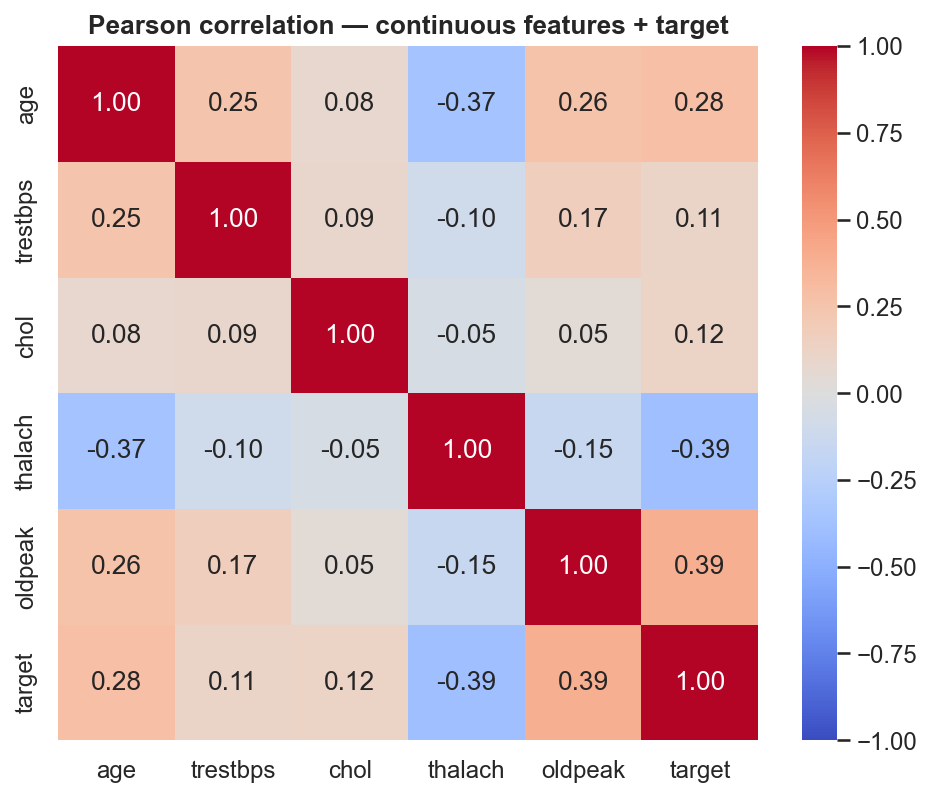

In [9]:
pearson_cols = continuous_cols + ["target"]
corr = df[pearson_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation — continuous features + target")
fig.tight_layout()
savefig(fig, "05_correlation_heatmap_pearson.png")
plt.show()

Saved /Users/ssvmindsprivatelimited/Desktop/MTech/MLOps/MLOps_S1-26_AIMLZG523_Assignment1/reports/figures/05b_correlation_heatmap_cramers_v.png


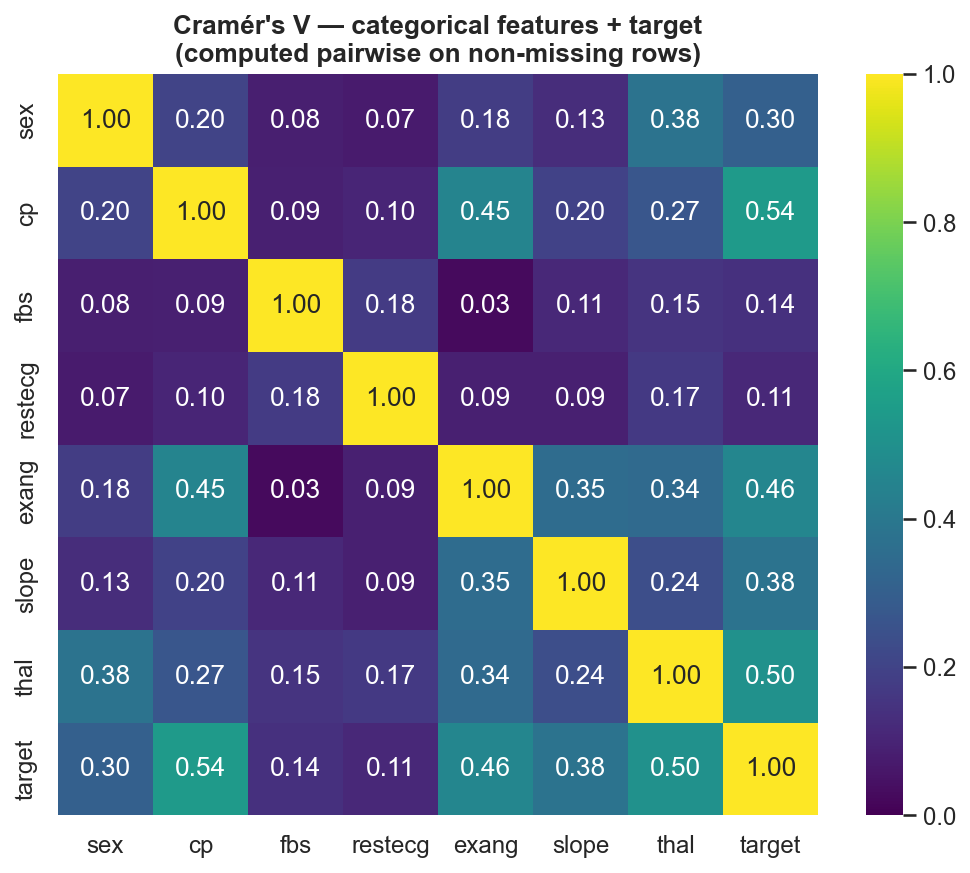

In [10]:
def cramers_v(x, y):
    confusion = pd.crosstab(x, y)
    chi2 = __import__("scipy.stats", fromlist=["chi2_contingency"]).chi2_contingency(confusion)[0]
    n = confusion.sum().sum()
    r, k = confusion.shape
    return float(np.sqrt((chi2 / n) / (min(r - 1, k - 1) or 1)))


cat_cols_for_v = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal", "target"]
v_matrix = pd.DataFrame(index=cat_cols_for_v, columns=cat_cols_for_v, dtype=float)
for c1 in cat_cols_for_v:
    for c2 in cat_cols_for_v:
        paired = df[[c1, c2]].dropna()
        v_matrix.loc[c1, c2] = 1.0 if c1 == c2 else cramers_v(paired[c1], paired[c2])

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(v_matrix.astype(float), annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax)
ax.set_title("Cramér's V — categorical features + target\n(computed pairwise on non-missing rows)")
fig.tight_layout()
savefig(fig, "05b_correlation_heatmap_cramers_v.png")
plt.show()

**Interpretation:** Pearson correlations among the continuous features
are modest (|r| mostly < 0.3); `thalach` (r=-0.39) and `oldpeak` (r=0.39)
are tied for the strongest target correlation, consistent with the KDE plot
above. In the Cramér's V
heatmap, `cp` (V=0.54), `thal` (V=0.50) and `exang` (V=0.46) show the
strongest association with `target`, again matching the count plots above
-- note `thal`'s V is computed only on its minority of non-missing rows
(mostly Cleveland), so it should be read as "informative where observed",
not as a property of the full dataset. No pair of categorical features
shows a near-1.0 Cramér's V with each other, so there is no obvious
redundant categorical pair to drop on multicollinearity grounds alone.

## 7. Boxplots by site — evidence of site shift

**What this drives:** whether `site` carries real distributional shift (it
does), which is the entire justification for running a leave-one-site-out
evaluation in addition to standard stratified k-fold CV.

Saved /Users/ssvmindsprivatelimited/Desktop/MTech/MLOps/MLOps_S1-26_AIMLZG523_Assignment1/reports/figures/06_boxplots_by_site.png


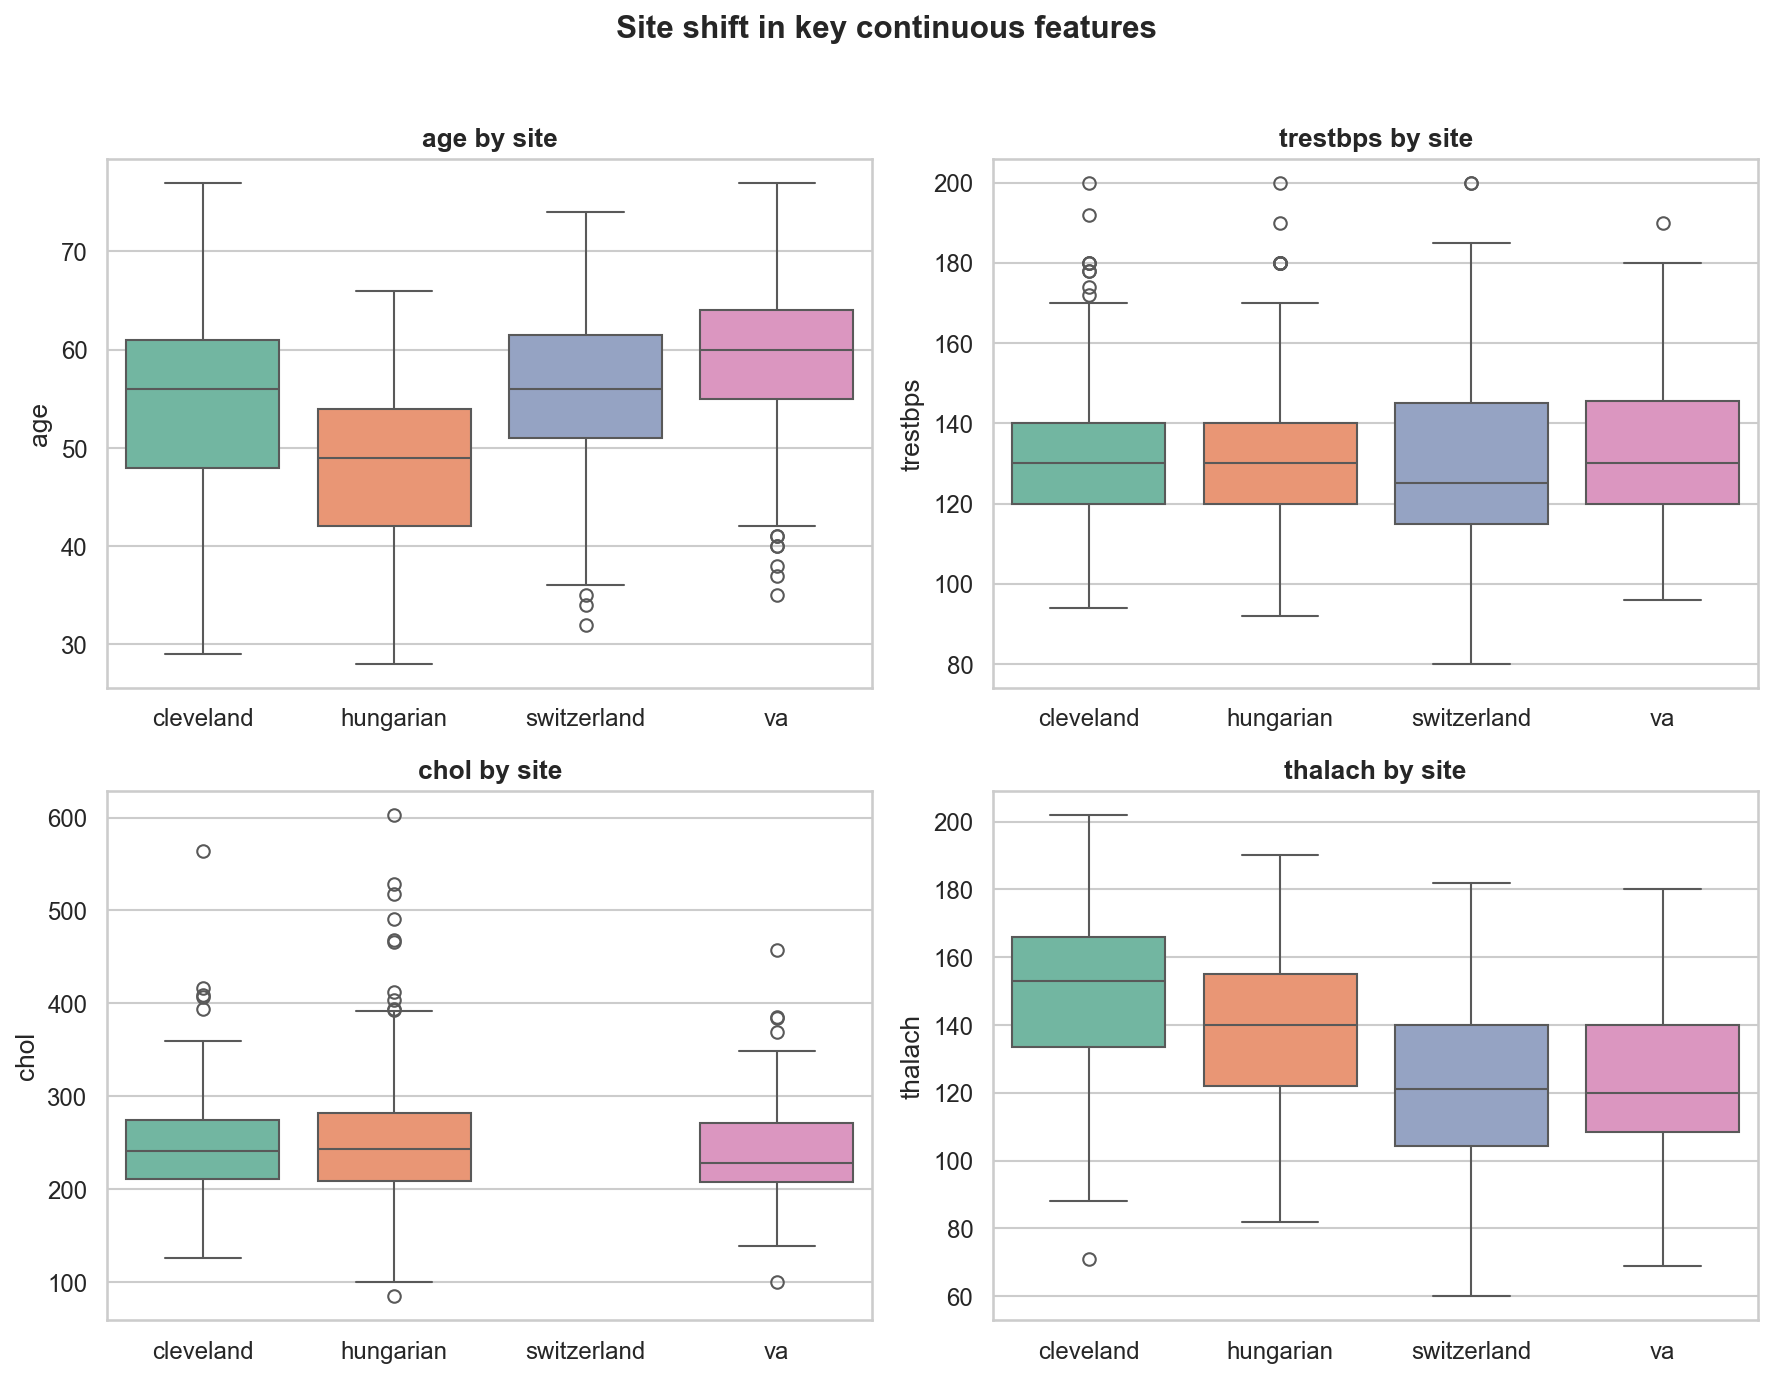

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()
for ax, col in zip(axes, ["age", "trestbps", "chol", "thalach"], strict=True):
    sns.boxplot(
        data=df,
        x="site",
        y=col,
        order=SITE_ORDER,
        ax=ax,
        hue="site",
        palette=SITE_PALETTE,
        legend=False,
    )
    ax.set_title(f"{col} by site")
    ax.set_xlabel("")
fig.suptitle("Site shift in key continuous features", y=1.02, fontweight="bold")
fig.tight_layout()
savefig(fig, "06_boxplots_by_site.png")
plt.show()

**Interpretation:** VA patients are visibly older on average with a
tighter spread; Switzerland's `trestbps` runs lower than the other three
sites; `chol` for Cleveland/Hungarian (the only sites with substantial
non-missing `chol`) differ in median and spread. These are exactly the kind
of shifts that make "train on everything, evaluate with one pooled k-fold"
optimistic about real-world generalisation to a new hospital -- a model that
never sees Switzerland during training may encounter a meaningfully
different `trestbps` distribution at serving time.

## 8. Summary: modelling implications

- **`ca`**: proposed to be **dropped** as a model feature (>95% missing
  outside Cleveland -- see `docs/DECISIONS.md` D2.5).
- **`thal`, `slope`**: proposed to be **kept with missing-indicator flags**,
  watched for site-leakage signals via feature importance and
  leave-one-site-out performance.
- **`site`**: proposed to be **excluded as a model feature**, used only for
  leave-one-site-out grouping and per-site metric reporting.
- **Class balance**: must be read per-site, not just pooled -- prevalence
  swings from 36% (Hungarian) to 93.5% (Switzerland).
- **Site shift** is real and visible in `age`, `trestbps` and `chol` --
  motivates the leave-one-site-out evaluation as a genuine generalisation
  check, separate from standard stratified k-fold CV.

These are proposals pending confirmation before Phase 3 implements them in
`src/heart_mlops/features/preprocess.py`.